# 05. 2PCF of the neurons of the fruit fly (3D)

**Question.** Are the neuron nuclei of the fruit fly clustered, and with which exponent?
This is the first 3D system of the project.

**Data.** `data/fly_neuron_net/neurons.zip`, 238 909 nuclei (FlyWire), x, y, z in nm.
**Outputs.** `out/05_fly_2pcf.csv`, `out/fly/fly_2pcf_*` (pickle for the SP fit).
**Paper.** Not in the current version.
**Code.** 3D functions at the end of `src/methods_two_point_correlation.py`
(`load_points_3d`, `sample_in_hull`, `pair_counts`, `PCF_with_variance_nd`).

Same protocol as `../2pcf_worm.ipynb` (Landy-Szalay with split random catalogues,
Keihänen et al. 2019). Three changes are needed in 3D, otherwise the 2D code runs
without error and measures something else.

| 2D code | problem on the fly | fix |
|---|---|---|
| `gdf.get_coordinates()` | drops z without warning | `include_z=True` |
| `gdf_edge.sample_points()` | samples a planar polygon | `sample_in_hull` (3D convex hull) |
| `distance.pdist` | 2.85·10¹⁰ pairs, 0.2 TB | dual KD-tree (`pair_counts`) |

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, cKDTree
from scipy.optimize import curve_fit

ROOT = Path.cwd().resolve().parent.parent           # repository root
sys.path.insert(0, str(ROOT / "src"))
import methods_two_point_correlation as mtpc
import save_load_pickle as slp

# Okabe-Ito palette, consistent with notebooks 01-03
C = {"data": "#000000", "fly": "#0072B2", "proj": "#D55E00",
     "random": "#999999", "fit": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

SEED = 42
rng = np.random.default_rng(SEED)
NM = 1e3                                     # 1 µm = 1000 nm, for display
DATA = ROOT / "data" / "fly_neuron_net" / "neurons.zip"
print("data:", DATA, "|", f"{DATA.stat().st_size/1e6:.1f} MB")

data: data/fly_neuron_net/neurons.zip | 8.8 MB


## 1. Data and domain

The random catalogue must fill the volume where neurons could be. We use the 3D convex
hull of the cloud (`scipy.spatial.ConvexHull`), the smallest convex volume containing
all points. A point is inside if it satisfies all face inequalities (`.equations`),
which gives a rejection sampler. The geojson of the repository is a planar hull and
cannot be used.

A brain is not convex, so the hull also contains empty space between the optic lobes
and the central brain. This inflates ξ, and section 8 measures by how much.

In [2]:
gdf = mtpc.load_points_3d(DATA)
X = mtpc.coords_3d(gdf)                      # (N, 3), include_z=True

hull = ConvexHull(X)
extent = X.max(axis=0) - X.min(axis=0)
bbox_vol = np.prod(extent)
rmin = mtpc.compute_rmin_nd(X)

print(f"N = {len(X):,} neurons".replace(",", " "))
print(f"extent (x, y, z) = {np.round(extent/NM, 1)} µm")
print(f"3D convex hull: {len(hull.vertices)} vertices, "
      f"volume {hull.volume/NM**3:.3e} µm³ "
      f"({100*hull.volume/bbox_vol:.0f} % of the bounding box)")
print(f"duplicated positions: {int(pd.DataFrame(X).duplicated().sum()):,}".replace(",", " "))
print(f"mean nearest-neighbour distance (rmin) = {rmin/NM:.2f} µm")
print(f"grid step in z: {np.gcd.reduce(np.unique(X[:, 2]).astype(np.int64))} nm "
      f"(slice thickness, negligible compared to rmin)")

N = 238 909 neurons
extent (x, y, z) = [815.3 391.5 278.5] µm
3D convex hull: 439 vertices, volume 3.930e+07 µm³ (44 % of the bounding box)
duplicated positions: 13 321
mean nearest-neighbour distance (rmin) = 1.96 µm
grid step in z: 40 nm (slice thickness, negligible compared to rmin)


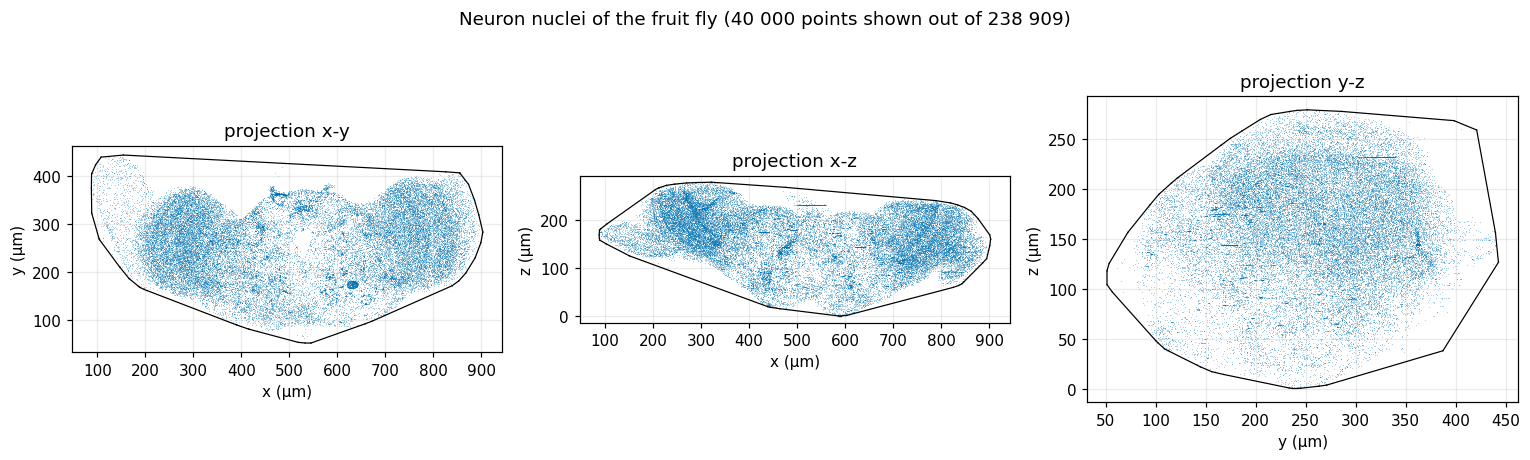

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
sub = X[rng.choice(len(X), 40000, replace=False)]     # subsample for display
for ax, (i, j), lbl in zip(axes, [(0, 1), (0, 2), (1, 2)], ["x-y", "x-z", "y-z"]):
    ax.scatter(sub[:, i]/NM, sub[:, j]/NM, s=0.4, alpha=0.25, color=C["fly"], lw=0)
    h2 = ConvexHull(X[:, [i, j]])
    for s in h2.simplices:
        ax.plot(X[s, i]/NM, X[s, j]/NM, color=C["data"], lw=0.8)
    ax.set_xlabel(f"{lbl[0]} (µm)"); ax.set_ylabel(f"{lbl[-1]} (µm)")
    ax.set_title(f"projection {lbl}"); ax.set_aspect("equal")
fig.suptitle("Neuron nuclei of the fruit fly (40 000 points shown out of 238 909)")
fig.tight_layout(); plt.show()

### The cloud in 3D and its projection

The right panel is what the 2D pipeline receives. Two neurons 200 µm apart can have the
same projection. The display cells use their own generator (`rng_v`).

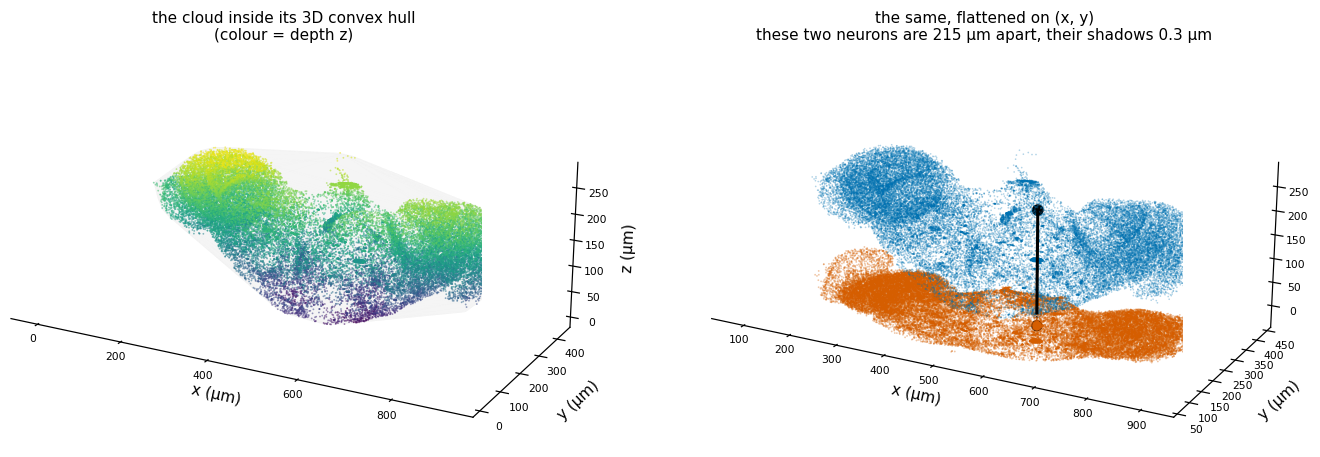

In [4]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

rng_v = np.random.default_rng(SEED + 1)      # stream dedicated to display
Xu    = X / NM                               # µm
sub3  = Xu[rng_v.choice(len(Xu), 40000, replace=False)]
z0    = Xu[:, 2].min() - 25                  # plane on which the shadow is projected

def view_3d(ax, zoom=1.45):
    ax.set_box_aspect(Xu.max(axis=0) - Xu.min(axis=0), zoom=zoom)
    ax.set_xlabel("x (µm)", labelpad=-6); ax.set_ylabel("y (µm)", labelpad=-6)
    ax.set_zlabel("z (µm)", labelpad=-8)
    ax.tick_params(labelsize=7, pad=-3); ax.grid(False)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_alpha(0)
    ax.view_init(elev=20, azim=-62)

fig = plt.figure(figsize=(13, 4.3))
ax = fig.add_subplot(121, projection="3d")
V = hull.points / NM
ax.add_collection3d(Poly3DCollection([V[s] for s in hull.simplices],
                                     facecolor="0.55", alpha=.045, edgecolor="none"))
ax.scatter(*sub3.T, c=sub3[:, 2], cmap="viridis", s=1.4, alpha=.55, lw=0)
ax.set_title("the cloud inside its 3D convex hull\n(colour = depth z)", fontsize=10)
view_3d(ax)

ax = fig.add_subplot(122, projection="3d")
ax.scatter(sub3[:, 0], sub3[:, 1], np.full(len(sub3), z0),
           color=C["proj"], s=1.4, alpha=.35, lw=0)                  # the shadow
ax.scatter(*sub3.T, color=C["fly"], s=1.2, alpha=.30, lw=0)          # the cloud
# the pair whose shadows overlap the most, with the largest z separation
pairs = cKDTree(Xu[:, :2]).query_pairs(1.0, output_type="ndarray")
i, j = pairs[np.argmax(np.abs(Xu[pairs[:, 0], 2] - Xu[pairs[:, 1], 2]))]
for k in (i, j):
    ax.plot([Xu[k, 0]] * 2, [Xu[k, 1]] * 2, [Xu[k, 2], z0], color="k", lw=.8, ls=":")
ax.plot(Xu[[i, j], 0], Xu[[i, j], 1], Xu[[i, j], 2], color="k", lw=2, zorder=20)
ax.scatter(Xu[[i, j], 0], Xu[[i, j], 1], Xu[[i, j], 2], color="k", s=45, zorder=21)
ax.scatter(Xu[[i, j], 0], Xu[[i, j], 1], [z0, z0], color=C["proj"], s=45, zorder=21,
           edgecolor="k", lw=.6)
d3 = np.linalg.norm(Xu[i] - Xu[j]); d2 = np.linalg.norm(Xu[i, :2] - Xu[j, :2])
ax.set_title(f"the same, flattened on (x, y)\nthese two neurons are {d3:.0f} µm apart, "
             f"their shadows {d2:.1f} µm", fontsize=10)
view_3d(ax)
fig.subplots_adjust(left=.01, right=.99, top=.86, bottom=.02, wspace=0)
plt.show()

## 2. The three 3D problems, checked on the data

In [5]:
# Pitfall 1: get_coordinates() drops z
xy_only = gdf.get_coordinates().to_numpy()
xyz     = gdf.get_coordinates(include_z=True).to_numpy()
print(f"pitfall 1, get_coordinates()                -> shape {xy_only.shape}  (z lost)")
print(f"           get_coordinates(include_z=True)  -> shape {xyz.shape}")
d2 = np.linalg.norm(xyz[:5000, :2] - xyz[0, :2], axis=1)
d3 = np.linalg.norm(xyz[:5000] - xyz[0], axis=1)
print(f"           distances to the first point: median underestimate of "
      f"{100*(1 - np.median(d2[1:]/d3[1:])):.0f} % if z is forgotten\n")

# Pitfall 2: sample_points() samples in a plane
import geopandas as gpd
gdf_edge = gpd.read_file(ROOT / "data" / "fly_neuron_net" / "fruitfly.geojson")
flat = gdf_edge.sample_points(1000).get_coordinates(include_z=True)
print(f"pitfall 2, geojson: {gdf_edge.geometry.iloc[0].geom_type}, "
      f"has_z={gdf_edge.geometry.iloc[0].has_z}")
print(f"           sample_points -> columns {list(flat.columns)}, "
      f"z all missing: {('z' not in flat) or bool(flat.get('z', pd.Series([0])).isna().all())}")
R_test = mtpc.sample_in_hull(hull, 1000, rng)
print(f"           sample_in_hull -> shape {R_test.shape}, "
      f"extent in z {np.ptp(R_test[:, 2])/NM:.0f} µm (the volume is filled)\n")

# Pitfall 3: the distance matrix
print(f"pitfall 3, pdist on {len(X):,} points = {len(X)*(len(X)-1)/2:.2e} pairs "
      f"= {len(X)*(len(X)-1)/2*8/1e12:.1f} TB in float64".replace(",", " "))
t0 = time.time(); _ = mtpc.pair_counts(X, np.array([0., rmin, 10*rmin]))
print(f"           pair_counts (dual KD-tree): {time.time()-t0:.1f} s, O(N) memory")

pitfall 1, get_coordinates()                -> shape (238909, 2)  (z lost)
           get_coordinates(include_z=True)  -> shape (238909, 3)
           distances to the first point: median underestimate of 9 % if z is forgotten

pitfall 2, geojson: Polygon, has_z=True
           sample_points -> columns ['x', 'y', 'z'], z all missing: True
           sample_in_hull -> shape (1000, 3), extent in z 265 µm (the volume is filled)

pitfall 3  pdist on 238 909 points = 2.85e+10 pairs = 0.2 TB in float64


           pair_counts (dual KD-tree): 1.2 s, O(N) memory


## 3. Parameters and control

- `rmin` = mean nearest-neighbour distance (2.0 µm).
- `rmax` = 35 % of the brain diagonal. Beyond it, pairs mostly see the border.
- `Nsample = 20 000` points per realisation. ξ is a ratio of pair densities and does not
  depend on random sub-sampling (checked at 10 k, 20 k and 40 k, within ±0.02).

Control: the same chain on a random catalogue drawn in the hull must give ξ ≈ 0.

In [6]:
N_run    = 4          # random catalogues per realisation
Nr_prime = 20000      # points per catalogue
N_real   = 8          # realisations (dispersion)
Nsample  = 20000      # data subsample per realisation
nbins    = 21
rmax     = 0.35 * np.linalg.norm(extent)

r_edges = np.logspace(np.log10(rmin), np.log10(rmax), nbins)
r_c     = np.sqrt(r_edges[:-1] * r_edges[1:])        # geometric bin centres
print(f"rmin = {rmin/NM:.2f} µm | rmax = {rmax/NM:.1f} µm | {nbins-1} log bins")

t0 = time.time()
R = mtpc.sample_in_hull(hull, Nsample, rng)
xi_random = mtpc.compute_two_point_correlation_nd(R, hull, r_edges, N_run, Nr_prime, rng)
print(f"random control: {time.time()-t0:.0f} s | "
      f"max|ξ| = {np.max(np.abs(xi_random)):.3f} | "
      f"median |ξ| = {np.median(np.abs(xi_random)):.4f}")

rmin = 1.96 µm | rmax = 331.2 µm | 20 log bins


random control: 13 s | max|ξ| = 0.026 | median |ξ| = 0.0015


## 4. 2PCF of the neurons

In [7]:
t0 = time.time()
l_xi = mtpc.PCF_with_variance_nd(X, hull, r_edges, N_run=N_run, Nr_prime=Nr_prime,
                                 k=N_real, Nsample=Nsample, rng=rng)
xi, xi_err = l_xi.mean(axis=0), l_xi.std(axis=0)
print(f"{N_real} realisations in {time.time()-t0:.0f} s")
print(pd.DataFrame({"r (µm)": np.round(r_c/NM, 2), "xi": np.round(xi, 3),
                    "sigma": np.round(xi_err, 3)}).to_string(index=False))

8 realisations in 99 s
 r (µm)     xi  sigma
   2.23 11.050  0.575
   2.88  8.133  0.494
   3.73  6.009  0.281
   4.82  4.335  0.152
   6.22  3.177  0.126
   8.04  2.335  0.057
  10.39  1.768  0.042
  13.43  1.368  0.016
  17.36  1.063  0.018
  22.43  0.854  0.013
  28.99  0.690  0.012
  37.46  0.562  0.010
  48.41  0.461  0.010
  62.55  0.370  0.009
  80.84  0.271  0.005
 104.47  0.168  0.005
 135.00  0.079  0.004
 174.46 -0.014  0.001
 225.45 -0.071  0.002
 291.35 -0.115  0.003


## 5. Power-law fit and correlation dimension

ξ(r) = (r/r₀)^(−γ), and D = d − γ is the correlation dimension (D = d for a uniform
cloud). `sp_helpers.fit_2pcf` bounds γ at 1.95, a 2D bound, so the fit is redone here
with the bound at 3, and we check that the optimum is not at the bound.

In [8]:
def power_law(r, gamma, r0):
    return (r / r0) ** (-gamma)

def fit_power_law(r, xi, err, dim, xi_min=0.05):
    # Fit on the bins where the signal is measurable. The bound on gamma comes
    # from the dimension of the space (D = dim - gamma >= 0).
    m = xi > xi_min
    popt, pcov = curve_fit(power_law, r[m], xi[m],
                           sigma=np.maximum(err[m], 0.02 * xi[m]),
                           p0=[1.0, r[m][0]],
                           bounds=([1e-3, 1.0], [dim, 1e9]), maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    return dict(gamma=popt[0], r0=popt[1], gamma_err=perr[0], r0_err=perr[1],
                nbins=int(m.sum()), r_range=(r[m][0], r[m][-1]),
                at_bound=bool(popt[0] > dim - 1e-2))

fit3d = fit_power_law(r_c, xi, xi_err, dim=3)
print(f"γ  = {fit3d['gamma']:.3f} ± {fit3d['gamma_err']:.3f}"
      f"   (bounded at 3, optimum at the bound? {fit3d['at_bound']})")
print(f"r0 = {fit3d['r0']/NM:.1f} ± {fit3d['r0_err']/NM:.1f} µm"
      f"   (fit error only, the choice of domain dominates, see section 8)")
print(f"D  = 3 − γ = {3 - fit3d['gamma']:.3f}")
print(f"fitted on {fit3d['nbins']} bins, "
      f"{fit3d['r_range'][0]/NM:.1f} → {fit3d['r_range'][1]/NM:.1f} µm")

γ  = 1.022 ± 0.036   (bounded at 3, optimum at the bound? False)
r0 = 19.5 ± 0.7 µm   (fit error only, the choice of domain dominates, see section 8)
D  = 3 − γ = 1.978
fitted on 17 bins, 2.2 → 135.0 µm


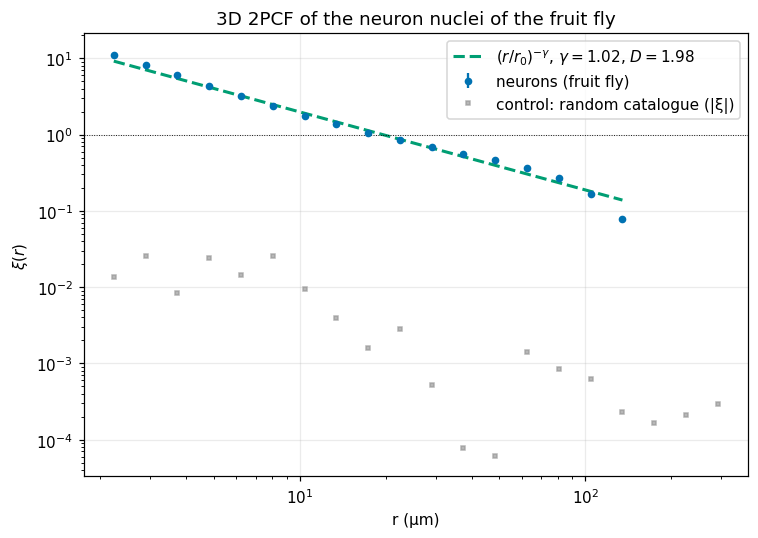

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(r_c/NM, xi, yerr=xi_err, fmt="o", ms=4, color=C["fly"],
            label="neurons (fruit fly)")
rr = np.logspace(np.log10(fit3d["r_range"][0]), np.log10(fit3d["r_range"][1]), 100)
ax.plot(rr/NM, power_law(rr, fit3d["gamma"], fit3d["r0"]), "--", color=C["fit"], lw=2,
        label=fr"$(r/r_0)^{{-\gamma}}$, $\gamma={fit3d['gamma']:.2f}$, $D={3-fit3d['gamma']:.2f}$")
ax.errorbar(r_c/NM, np.abs(xi_random), fmt="s", ms=3, color=C["random"], alpha=0.7,
            label="control: random catalogue (|ξ|)")
ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("3D 2PCF of the neuron nuclei of the fruit fly")
ax.legend(); fig.tight_layout(); plt.show()

## 6. Cross-check by counting neighbours (Davis-Peebles)

Mean number of neurons in a ball of radius r around a neuron, divided by the same mean
around a random point of the hull,

$$1+\bar\xi(<r) = \frac{\langle N(<r)\rangle_{\text{neuron}}}{\langle N(<r)\rangle_{\text{random}}} = \frac{N_R}{N_D}\frac{DD(<r)}{DR(<r)}$$

Differences between balls give shells, hence ξ(r). This estimator does not share the
code path of Landy-Szalay, so it checks the normalisation of section 4. It shares the
same hull, so it does not check the domain.

ball of r = 15 µm, mean over 2000 centres:
  around a neuron       :  246.4 neighbours
  around any point      :   83.3 neighbours  (uniform expectation: 85.9)
  1 + xi(<15 µm) = 2.96


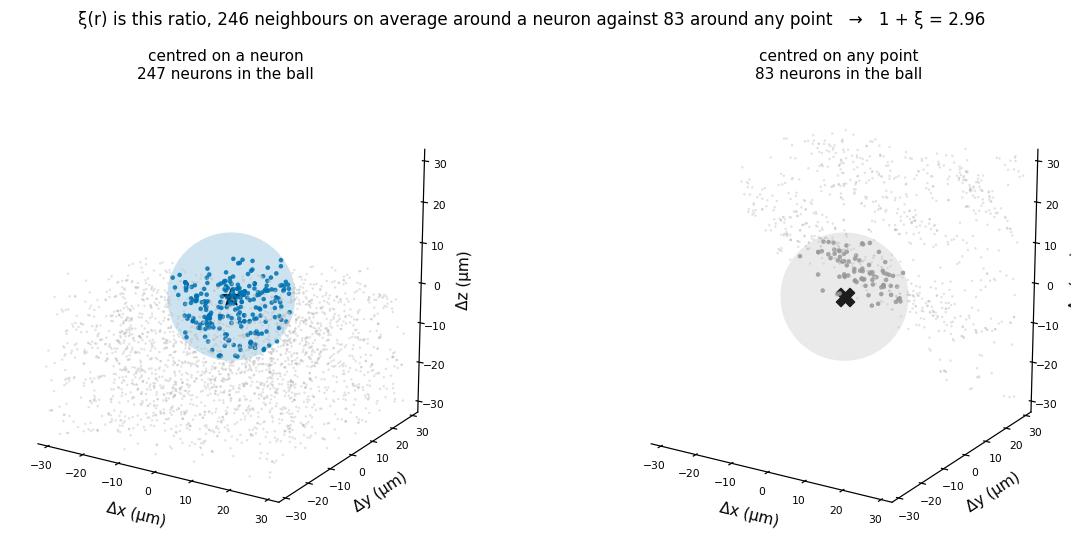

In [10]:
rng_v  = np.random.default_rng(SEED + 1)     # same dedicated stream, independent of rng
tree   = cKDTree(X)
R_ball = 15 * NM                             # ball radius, of the order of r0
n_cent = 2000

cen_d = X[rng_v.choice(len(X), n_cent, replace=False)]      # centres = neurons
cen_r = mtpc.sample_in_hull(hull, n_cent, rng_v)            # centres = points of the volume
n_d = np.array([len(a) for a in tree.query_ball_point(cen_d, R_ball, workers=-1)]) - 1
n_r = np.array([len(a) for a in tree.query_ball_point(cen_r, R_ball, workers=-1)])
print(f"ball of r = {R_ball/NM:.0f} µm, mean over {n_cent} centres:")
print(f"  around a neuron       : {n_d.mean():6.1f} neighbours")
print(f"  around any point      : {n_r.mean():6.1f} neighbours  "
      f"(uniform expectation: {len(X) * 4/3*np.pi*R_ball**3 / hull.volume:.1f})")
print(f"  1 + xi(<{R_ball/NM:.0f} µm) = {n_d.mean()/n_r.mean():.2f}")

# We draw one centre of each type, chosen with the count closest to the mean,
# so that the figure shows what the ratio above measures.
u, v = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
sphere = np.array([np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v)]) * R_ball / NM
half = 2.1 * R_ball
fig = plt.figure(figsize=(11.5, 5))
for k, (cen, n, col, mark, ttl) in enumerate([
        (cen_d[np.argmin(abs(n_d - n_d.mean()))], n_d, C["fly"], "*", "centred on a neuron"),
        (cen_r[np.argmin(abs(n_r - n_r.mean()))], n_r, C["random"], "X", "centred on any point")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    P = (X[tree.query_ball_point(cen, half * np.sqrt(3), workers=-1)] - cen) / NM
    P = P[(np.abs(P) <= half / NM).all(axis=1)]
    inside = np.linalg.norm(P, axis=1) <= R_ball / NM
    ax.scatter(*P[~inside].T, color="0.75", s=2.5, alpha=.45, lw=0)
    ax.scatter(*P[inside].T, color=col, s=9, alpha=.85, lw=0)
    ax.plot_surface(*sphere, color=col, alpha=.10, lw=0, shade=False)
    ax.scatter([0], [0], [0], color="k", marker=mark, s=140, zorder=20)
    ax.set_title(f"{ttl}\n{int(inside.sum())} neurons in the ball", fontsize=10)
    L = half / NM
    ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_zlim(-L, L)
    ax.set_box_aspect((1, 1, 1), zoom=1.1)
    ax.set_xlabel("Δx (µm)", labelpad=-4); ax.set_ylabel("Δy (µm)", labelpad=-4)
    ax.set_zlabel("Δz (µm)", labelpad=-4)
    ax.tick_params(labelsize=7, pad=-2); ax.grid(False)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_alpha(0)
    ax.view_init(elev=18, azim=-58)
fig.suptitle(f"ξ(r) is this ratio, {n_d.mean():.0f} neighbours on average around a neuron "
             f"against {n_r.mean():.0f} around any point   →   "
             f"1 + ξ = {n_d.mean()/n_r.mean():.2f}", fontsize=11)
fig.subplots_adjust(left=.02, right=.98, top=.84, bottom=.06, wspace=.02)
plt.show()

### Counting at all radii

The excess of neighbours around a neuron grows as r^D, which gives D without fitting a
power law to ξ. The shell ratio is compared with the Landy-Szalay ξ of section 4.

slope of N(<r) around any point : 2.91  (ball volume: 3)
slope of the neighbour excess   : 1.89  (correlation dimension, 3 - γ = 1.98)
gap to the Landy-Szalay ξ between 2.2 and 135 µm: median 4 %, max 29 % (at r = 135 µm, where ξ = 0.08)


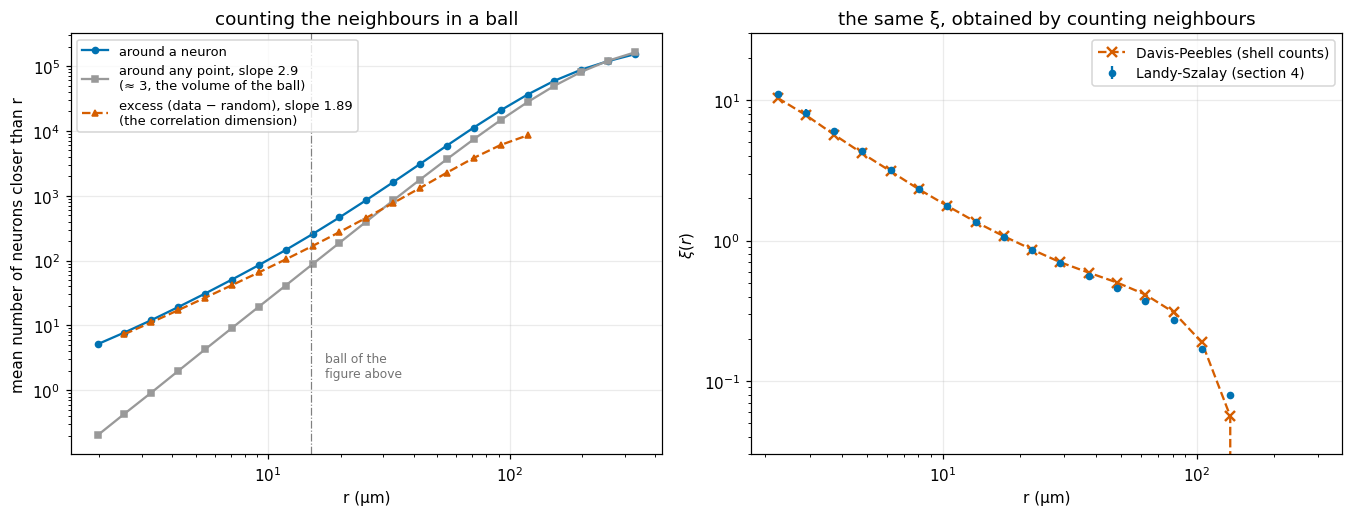

In [11]:
N_cent = 20000
cen_d  = X[rng_v.choice(len(X), N_cent, replace=False)]
cen_r  = mtpc.sample_in_hull(hull, N_cent, rng_v)
# count_neighbors gives cumulative counts at each bin edge, in O(N log N)
cum_d = tree.count_neighbors(cKDTree(cen_d), r_edges) / N_cent - 1.0   # -1: the centre itself
cum_r = tree.count_neighbors(cKDTree(cen_r), r_edges) / N_cent
xi_shell = np.diff(cum_d) / np.diff(cum_r) - 1        # differential version: the shells
excess   = cum_d - cum_r

r_lo, r_hi = fit3d["r_range"]                         # the range fitted in section 5
m    = (r_edges >= r_lo) & (r_edges <= r_hi) & (excess > 0)
bins = (r_c >= r_lo) & (r_c <= r_hi) & (xi > 0) & (xi_shell > 0)
D_count = np.polyfit(np.log(r_edges[m]), np.log(excess[m]), 1)[0]
p_rand  = np.polyfit(np.log(r_edges[m]), np.log(cum_r[m]), 1)[0]
gap     = 100 * np.abs(xi_shell[bins] / xi[bins] - 1)
r_worst = r_c[bins][np.argmax(gap)]
print(f"slope of N(<r) around any point : {p_rand:.2f}  (ball volume: 3)")
print(f"slope of the neighbour excess   : {D_count:.2f}  "
      f"(correlation dimension, 3 - γ = {3 - fit3d['gamma']:.2f})")
print(f"gap to the Landy-Szalay ξ between {r_lo/NM:.1f} and {r_hi/NM:.0f} µm: "
      f"median {np.median(gap):.0f} %, max {gap.max():.0f} % (at r = {r_worst/NM:.0f} µm, "
      f"where ξ = {xi[bins][np.argmax(gap)]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8))
ax = axes[0]
ax.plot(r_edges/NM, cum_d, "o-", color=C["fly"], ms=4, label="around a neuron")
ax.plot(r_edges/NM, cum_r, "s-", color=C["random"], ms=4,
        label=f"around any point, slope {p_rand:.1f}\n(≈ 3, the volume of the ball)")
ax.plot(r_edges[m]/NM, excess[m], "^--", color=C["proj"], ms=4,
        label=f"excess (data − random), slope {D_count:.2f}\n(the correlation dimension)")
ax.axvline(R_ball/NM, color="0.5", lw=.8, ls="-.")
ax.text(R_ball/NM*1.15, 1.6, "ball of the\nfigure above", fontsize=8, color="0.45")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel("mean number of neurons closer than r")
ax.set_title("counting the neighbours in a ball")
ax.legend(fontsize=8.5, loc="upper left")

ax = axes[1]
ax.errorbar(r_c/NM, xi, yerr=xi_err, fmt="o", ms=4, color=C["fly"], label="Landy-Szalay (section 4)")
ax.plot(r_c/NM, xi_shell, "x--", color=C["proj"], ms=7, mew=1.6,
        label="Davis-Peebles (shell counts)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(3e-2, 3e1)
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("the same ξ, obtained by counting neighbours")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

## 7. What the 2D code would give

Same estimator on the (x, y) projection with its 2D hull, which is what the original
pipeline produces on these data.

In [12]:
X2 = X[:, :2]
hull2 = ConvexHull(X2)
t0 = time.time()
l_xi2 = mtpc.PCF_with_variance_nd(X2, hull2, r_edges, N_run=N_run, Nr_prime=Nr_prime,
                                  k=N_real, Nsample=Nsample, rng=rng)
xi2, xi2_err = l_xi2.mean(axis=0), l_xi2.std(axis=0)
fit2d = fit_power_law(r_c, xi2, xi2_err, dim=2)
print(f"projection (x,y): {time.time()-t0:.0f} s")
print(f"  γ = {fit2d['gamma']:.3f} ± {fit2d['gamma_err']:.3f} (bounded at 2), "
      f"r0 = {fit2d['r0']/NM:.1f} µm, D = 2 − γ = {2 - fit2d['gamma']:.3f}")
print(f"\ncomparison at the first bin (r = {r_c[0]/NM:.1f} µm): "
      f"ξ_3D = {xi[0]:.2f} against ξ_2D = {xi2[0]:.2f} "
      f"({xi[0]/xi2[0]:.1f}× lower in projection)")

projection (x,y): 46 s
  γ = 0.457 ± 0.055 (bounded at 2), r0 = 3.1 µm, D = 2 − γ = 1.543

comparison at the first bin (r = 2.2 µm): ξ_3D = 11.05 against ξ_2D = 0.95 (11.6× lower in projection)


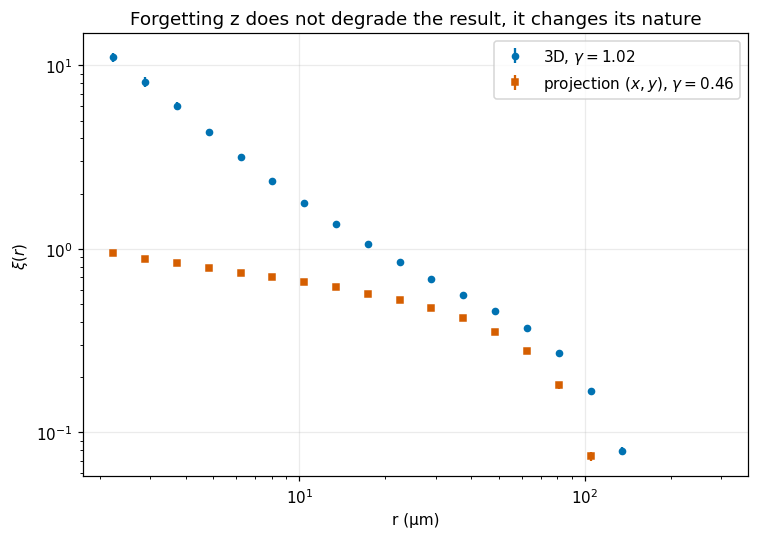

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(r_c/NM, xi, yerr=xi_err, fmt="o", ms=4, color=C["fly"],
            label=fr"3D, $\gamma={fit3d['gamma']:.2f}$")
ax.errorbar(r_c/NM, xi2, yerr=xi2_err, fmt="s", ms=4, color=C["proj"],
            label=fr"projection $(x,y)$, $\gamma={fit2d['gamma']:.2f}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("Forgetting z does not degrade the result, it changes its nature")
ax.legend(); fig.tight_layout(); plt.show()

## 8. Effect of the domain

If the hull matched the occupied volume, a random point would lie at about rmin from
the nearest neuron.

In [14]:
d_rand, _ = cKDTree(X).query(mtpc.sample_in_hull(hull, 50000, rng), workers=-1)
d_data, _ = cKDTree(X).query(X, k=2, workers=-1)
frac_far = np.mean(d_rand > 5 * rmin)
print(f"distance to the nearest neuron:")
print(f"  from a random point: median {np.median(d_rand)/NM:.1f} µm")
print(f"  from a neuron      : median {np.median(d_data[:, 1])/NM:.1f} µm (= rmin)")
print(f"  {100*frac_far:.0f} % of the random points are more than 5·rmin "
      f"({5*rmin/NM:.0f} µm) away from any neuron, empty volume that the convex hull "
      f"wrongly counts as habitable.")

distance to the nearest neuron:
  from a random point: median 4.9 µm
  from a neuron      : median 1.6 µm (= rmin)
  28 % of the random points are more than 5·rmin (10 µm) away from any neuron, empty volume that the convex hull wrongly counts as habitable.


### Four domains

ξ compares where the points are with where they could be, so the domain is part of the
null hypothesis. We compare the bounding box, the hull, and the union of the grid cells
of size c (20 and 5 µm) that contain at least one neuron.

In [15]:
# The domain IS the null hypothesis: xi compares where the points are with where
# they could have been. We compute xi with four domains, from the widest to the
# tightest, to separate what is measured from what is assumed.
rng_dom = np.random.default_rng(SEED)        # local, so the cell is reproducible alone

def sampler_hull(h):
    return lambda n, g: mtpc.sample_in_hull(h, n, g)

def sampler_voxels(cell):
    """Union of the cells of a grid of step `cell` containing >= 1 neuron, the
    smallest domain containing all nodes at resolution `cell`."""
    lo = X.min(axis=0)
    keys = np.unique(np.floor((X - lo) / cell).astype(np.int64), axis=0)
    return (lambda n, g: lo + (keys[g.integers(0, len(keys), n)] + g.random((n, 3))) * cell,
            len(keys) * cell**3)

def xi_domain(sampler, k=4):
    """Same estimator as in section 4, only the source of the random catalogue changes."""
    out = []
    for _ in range(k):
        sub = X[rng_dom.choice(len(X), Nsample, replace=False)]
        DD = mtpc.pair_counts(sub, r_edges)
        DR, RR = np.zeros(nbins - 1), np.zeros(nbins - 1)
        for _ in range(N_run):
            R_cat = sampler(Nr_prime, rng_dom)
            DR += mtpc.pair_counts(sub, r_edges, B=R_cat)
            RR += mtpc.pair_counts(R_cat, r_edges)
        out.append(mtpc.compute_LS_correlation_2019(DD, DR, RR, len(sub),
                                                    Nr_prime, Nr_prime * N_run))
    return np.array(out)

corners = np.array(np.meshgrid(*zip(X.min(axis=0), X.max(axis=0)))).reshape(3, -1).T
s20, v20 = sampler_voxels(20 * NM)
s05, v05 = sampler_voxels(5 * NM)
domains = [("bounding box",  sampler_hull(ConvexHull(corners)), bbox_vol),
           ("convex hull",   sampler_hull(hull),                hull.volume),
           ("voxels 20 µm",  s20,                               v20),
           ("voxels 5 µm",   s05,                               v05)]

print(f"{'domain':<18}{'V/V_hull':>9}{'ξ(2.2 µm)':>11}{'γ':>17}{'r0 (µm)':>16}{'bins':>6}")
for name, s, v in domains:
    l_xi_d = xi_domain(s)
    xi_d, err_d = l_xi_d.mean(axis=0), l_xi_d.std(axis=0)
    f = fit_power_law(r_c, xi_d, err_d, dim=3)
    print(f"{name:<18}{v/hull.volume:>9.2f}{xi_d[0]:>11.2f}"
          f"{f['gamma']:>11.3f} ± {f['gamma_err']:.3f}"
          f"{f['r0']/NM:>9.1f} ± {f['r0_err']/NM:.1f}{f['nbins']:>6}")

domain             V/V_hull  ξ(2.2 µm)                γ         r0 (µm)  bins


bounding box           2.26      25.00      1.038 ± 0.072     55.6 ± 6.0    17


convex hull            1.00      10.16      1.033 ± 0.043     19.2 ± 0.9    17


voxels 20 µm           0.83       8.56      1.164 ± 0.026     13.2 ± 0.3    17


voxels 5 µm            0.30       3.12      1.719 ± 0.074      5.0 ± 0.2    10


- From the box to the hull (volume ×2.26), γ does not move (1.038 → 1.033) and r₀ is
  divided by 2.9. The amplitude depends on the mean density N/V, the slope does not.
- When the domain is tightened onto the data (voxels), ξ drops. In the limit c → rmin
  the domain is the cloud itself and ξ = 0. A domain fitted to the data cannot test the
  data, and a grid also adds porosity at the scale of the cell.

A domain independent of the cloud (FlyWire neuropil meshes) would remove the bias.
Otherwise, data and model should be compared with the same domain, as in the rest of the
project.

## 9. Candidate η for the SP fit

Silhouette score of a k-means on a sub-sample. In 3D the relation of the worm notebook
`λ = η^(1/(2−γ))` becomes `η^(1/(3−γ))`.

silhouette: {2: np.float64(0.56), 3: np.float64(0.447), 4: np.float64(0.36), 5: np.float64(0.36), 6: np.float64(0.296), 7: np.float64(0.279), 8: np.float64(0.278), 9: np.float64(0.284), 10: np.float64(0.293), 11: np.float64(0.284), 12: np.float64(0.286)}
candidate η (5 best): [2, 3, 5, 4, 6]


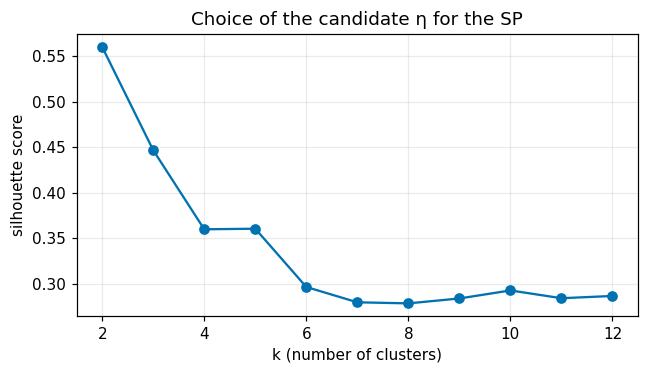

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

S = X[rng.choice(len(X), 20000, replace=False)]
kmax, scores = 12, []
for k in range(2, kmax + 1):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(S)
    scores.append(silhouette_score(S[:5000], km.labels_[:5000]))
scores = np.array(scores)
l_cluster = (np.arange(2, kmax + 1)[np.argsort(scores)[::-1]][:5]).tolist()
print("silhouette:", dict(zip(range(2, kmax + 1), np.round(scores, 3))))
print("candidate η (5 best):", l_cluster)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(2, kmax + 1), scores, "o-", color=C["fly"])
ax.set_xlabel("k (number of clusters)"); ax.set_ylabel("silhouette score")
ax.set_title("Choice of the candidate η for the SP")
fig.tight_layout(); plt.show()

## 10. Saving

Pickle in the format of `fit_Soneira_Peebles` (plus `hull_points` and `dim`) and a
summary CSV.

In [17]:
out_dir = ROOT / "out" / "fly"
out_dir.mkdir(parents=True, exist_ok=True)

# Distance distribution, for the KL divergence of the SP fit. The worm notebook stores
# the raw distances, here there would be 2.85e10 of them, so we store the histogram on
# r_edges, computed on a larger subsample than the one of the 2PCF.
DD_counts = mtpc.pair_counts(X[rng.choice(len(X), 50000, replace=False)], r_edges)

d_save = {
    "r_edges": r_edges, "r_centers": r_c,
    "xi": l_xi, "xi_random": xi_random,
    "distance_distribution": DD_counts,      # counts per bin (50 000 points)
    "fit_SP": (fit3d["gamma"], fit3d["r0"]),
    "clustering": l_cluster,
    "number_points": len(X),
    "dim": 3,                                # <- the SP fit must use 3-gamma, not 2-gamma
    "hull_points": X[hull.vertices],         # 3D convex hull (domain)
    "params": dict(N_run=N_run, Nr_prime=Nr_prime, N_real=N_real, Nsample=Nsample,
                   nbins=nbins, rmin=rmin, rmax=rmax, scale="log", seed=SEED),
}
pkl = out_dir / f"fly_2pcf_{N_run}_{Nr_prime}_{N_real}_{Nsample}_{nbins}"
slp.save_results(pkl, d_save)
print("->", pkl)

df = pd.DataFrame({
    "r_nm": r_c, "r_um": r_c / NM,
    "xi_3d": xi, "xi_3d_std": xi_err,
    "xi_proj_xy": xi2, "xi_proj_xy_std": xi2_err,
    "xi_random_control": xi_random,
})
out_csv = ROOT / "out" / "05_fly_2pcf.csv"
df.to_csv(out_csv, index=False)
print("->", out_csv)

summary = pd.DataFrame([
    dict(case="3D (x,y,z)", gamma=fit3d["gamma"], gamma_err=fit3d["gamma_err"],
         r0_um=fit3d["r0"]/NM, dim=3, D=3 - fit3d["gamma"], xi_first_bin=xi[0]),
    dict(case="projection (x,y)", gamma=fit2d["gamma"], gamma_err=fit2d["gamma_err"],
         r0_um=fit2d["r0"]/NM, dim=2, D=2 - fit2d["gamma"], xi_first_bin=xi2[0]),
])
summary.to_csv(ROOT / "out" / "05_fly_2pcf_summary.csv", index=False)
print(summary.round(3).to_string(index=False))

-> out/fly/fly_2pcf_4_20000_8_20000_21
-> out/05_fly_2pcf.csv
            case  gamma  gamma_err  r0_um  dim     D  xi_first_bin
      3D (x,y,z)  1.022      0.036 19.522    3 1.978        11.050
projection (x,y)  0.457      0.055  3.130    2 1.543         0.952


## Results

| | γ | r₀ | D | ξ at 2.2 µm |
|---|---|---|---|---|
| 3D (x, y, z) | 1.02 ± 0.04 | 19.5 µm | 1.98 | 11.05 |
| projection (x, y) | 0.46 ± 0.06 | 3.1 µm | 1.54 | 0.95 |

- The neurons are clustered. ξ is a power law over 1.8 decades (2.2 to 135 µm) with
  D = 1.98, a structure of dimension about 2 in a 3D volume. The random control gives
  max|ξ| = 0.026.
- Counting neighbours gives 1 + ξ(<15 µm) = 2.96 and an excess growing as r^1.89. The
  counted ξ agrees with Landy-Szalay within 4 % (median) over the fitted range.
- The projection divides the amplitude by 11.6 and the slope by 2. The value 0.46 is in
  the range of the geographic systems, so nothing in the number signals the error.
- The hull leaves 28 % of the random points more than 10 µm from any neuron. γ does not
  depend on the convex domain, r₀ does (13 to 56 µm). D can be quoted, r₀ only as an
  order of magnitude (about 20 µm within a factor 3).
- Best silhouette for η = 2, then 3. The 3D SP fit is in notebook 05bis.